# Poker Hand Model Training

This notebook is a separate, runnable companion to `poker_hand_analysis.ipynb`. It reads `poker+hand.zip` directly and compares a majority-class baseline, a decision tree, and a random forest.

**Goal:** Predict the hand category (`CLASS`, codes 0-9) from the suits and ranks of five cards.

**Workflow:** Validate the supplied training records, remove repeated unordered hands, create a training/validation split, compare models using validation macro F1, and inspect errors. Final evaluation on the supplied test file is an optional step at the end.

The earlier analysis has already summarized both supplied files. Document that exposure in the report. Keep test results out of model selection.

## 1. Setup

Keep this notebook and `poker+hand.zip` in the project folder. Select a Python kernel and run the cells from top to bottom. No extraction is needed.

If the imports fail, uncomment and run the installation cell below in the selected kernel, then restart the kernel if requested. The notebook records package versions for reproducibility. The installation command is commented out so running all cells does not automatically change your environment.

In [1]:
# Uncomment this line to install the required packages in this notebook's kernel.
# %pip install pandas matplotlib scikit-learn ipykernel

In [2]:
from pathlib import Path
import platform
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
CLASS_CODES = list(range(10))
CLASS_LABELS = {
    0: "High card",
    1: "One pair",
    2: "Two pairs",
    3: "Three of a kind",
    4: "Straight",
    5: "Flush",
    6: "Full house",
    7: "Four of a kind",
    8: "Straight flush",
    9: "Royal flush",
}
FEATURE_COLUMNS = [
    column for i in range(1, 6) for column in (f"S{i}", f"C{i}")
]
COLUMNS = FEATURE_COLUMNS + ["CLASS"]
SUIT_COLUMNS = [f"S{i}" for i in range(1, 6)]
RANK_COLUMNS = [f"C{i}" for i in range(1, 6)]

archive_path = Path("poker+hand.zip")
if not archive_path.is_file():
    raise FileNotFoundError(
        "Keep poker+hand.zip beside this notebook and run from the project folder."
    )

print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("matplotlib:", plt.matplotlib.__version__)
print("scikit-learn:", sklearn.__version__)

Python: 3.12.4
pandas: 3.0.6
NumPy: 2.5.3
matplotlib: 3.11.2
scikit-learn: 1.9.1


## 2. Load and validate the training data

Only the supplied training file is loaded during development. `CLASS` is the target; it must never appear in the model inputs.

Check missing values, integer values, suit codes (1-4), rank codes (1-13), category codes (0-9), and repeated cards within each hand. Ace is rank 1; a straight can use Ace low or high, which a raw-input model must learn from examples.

In [3]:
def validate_records(frame):
    if list(frame.columns) != COLUMNS or frame.empty:
        raise ValueError("Expected nonempty records with ten features and CLASS.")
    if frame.isna().any().any():
        raise ValueError("Missing values found.")
    values = frame.to_numpy(dtype=np.float64)
    if not np.isfinite(values).all() or not (values == np.floor(values)).all():
        raise ValueError("All suit, rank, and category codes must be integers.")
    if not frame[SUIT_COLUMNS].isin(range(1, 5)).all().all():
        raise ValueError("Suit codes must be between 1 and 4.")
    if not frame[RANK_COLUMNS].isin(range(1, 14)).all().all():
        raise ValueError("Rank codes must be between 1 and 13.")
    if not frame["CLASS"].isin(CLASS_CODES).all():
        raise ValueError("CLASS must be between 0 and 9.")

    suits = frame[SUIT_COLUMNS].to_numpy(dtype=np.int64)
    ranks = frame[RANK_COLUMNS].to_numpy(dtype=np.int64)
    card_ids = (suits - 1) * 13 + ranks - 1
    if (np.diff(np.sort(card_ids, axis=1), axis=1) == 0).any():
        raise ValueError("A hand contains the same card more than once.")


def unordered_hand_keys(frame):
    # A base-52 key uniquely identifies a set of five cards, ignoring their order.
    # It is used for duplicate/overlap checks only, never as a model feature.
    suits = frame[SUIT_COLUMNS].to_numpy(dtype=np.int64)
    ranks = frame[RANK_COLUMNS].to_numpy(dtype=np.int64)
    ordered_cards = np.sort((suits - 1) * 13 + ranks - 1, axis=1)
    powers = 52 ** np.arange(5, dtype=np.int64)
    return pd.Series(
        (ordered_cards * powers).sum(axis=1),
        index=frame.index,
        name="hand_key",
    )


with zipfile.ZipFile(archive_path) as archive:
    with archive.open("poker-hand-training-true.data") as file:
        train_data = pd.read_csv(file, header=None, names=COLUMNS)

validate_records(train_data)
print(f"Supplied training records: {len(train_data):,}")
print("Range, missing-value, integer, and repeated-card checks passed.")
display(train_data.head())

Supplied training records: 25,010
Range, missing-value, integer, and repeated-card checks passed.


,S1,C1,S2,C2,S3,C3,S4,C4,S5,C5,CLASS
0,1,10,1,11,1,13,1,12,1,1,9
1,2,11,2,13,2,10,2,12,2,1,9
2,3,12,3,11,3,13,3,10,3,1,9
3,4,10,4,11,4,1,4,13,4,12,9
4,4,1,4,13,4,12,4,11,4,10,9


## 3. Remove duplicate unordered hands

The same five cards can appear in different orders. Remove extra copies before splitting so the same hand cannot appear in both training and validation. Reject conflicting labels rather than silently choosing one.

This check groups identical card sets. It does not group different hands related by renaming suits. The first supplied ordering is retained for each hand; card-order invariance is a future experiment.

In [4]:
train_keys = unordered_hand_keys(train_data)
labels_per_hand = train_data["CLASS"].groupby(train_keys).nunique()
if (labels_per_hand > 1).any():
    raise ValueError("Identical unordered hands have conflicting category labels.")

keep = ~train_keys.duplicated()
development = train_data.loc[keep].copy()
development_keys = train_keys.loc[keep]

print(f"Repeated unordered hands removed: {(~keep).sum():,}")
print(f"Distinct development hands: {len(development):,}")

class_counts = pd.DataFrame({
    "Category": pd.Series(CLASS_LABELS),
    "Supplied training": train_data["CLASS"].value_counts(),
    "After deduplication": development["CLASS"].value_counts(),
}).reindex(CLASS_CODES)
display(class_counts)

Repeated unordered hands removed: 112
Distinct development hands: 24,898


,Category,Supplied training,After deduplication
0,High card,12493,12441
1,One pair,10599,10545
2,Two pairs,1206,1202
3,Three of a kind,513,512
4,Straight,93,93
5,Flush,54,54
6,Full house,36,36
7,Four of a kind,6,6
8,Straight flush,5,5
9,Royal flush,5,4


## 4. Create a reproducible training/validation split

Use 80% of distinct development hands for fitting and 20% for validation. Stratification attempts to preserve class proportions. The supplied test file remains separate.

Inspect the counts below. The training file has only five royal-flush rows, representing four distinct hands; a validation score based on one rare hand is highly uncertain. Macro F1 averages the F1 scores of all ten categories equally, so such uncertainty also affects model selection.

This is a starter comparison on one split. Repeated validation with feasible class counts is a later step before making strong claims about which model is best.

In [5]:
X_development = development[FEATURE_COLUMNS]
y_development = development["CLASS"]

if y_development.value_counts().min() < 2:
    raise ValueError("Every represented category needs at least two distinct hands.")

X_train, X_validation, y_train, y_validation = train_test_split(
    X_development,
    y_development,
    test_size=0.20,
    stratify=y_development,
    random_state=RANDOM_STATE,
)

training_keys = set(development_keys.loc[X_train.index])
validation_keys = set(development_keys.loc[X_validation.index])
if not training_keys.isdisjoint(validation_keys):
    raise RuntimeError("An identical unordered hand crossed the validation split.")

split_counts = pd.DataFrame({
    "Category": pd.Series(CLASS_LABELS),
    "Training": y_train.value_counts(),
    "Validation": y_validation.value_counts(),
}).reindex(CLASS_CODES).fillna(0)
split_counts[["Training", "Validation"]] = (
    split_counts[["Training", "Validation"]].astype(int)
)
display(split_counts)
print(f"Training: {len(X_train):,}; validation: {len(X_validation):,}")

,Category,Training,Validation
0,High card,9953,2488
1,One pair,8436,2109
2,Two pairs,961,241
3,Three of a kind,410,102
4,Straight,74,19
5,Flush,43,11
6,Full house,29,7
7,Four of a kind,5,1
8,Straight flush,4,1
9,Royal flush,3,1


Training: 19,918; validation: 4,980


## 5. Fit and compare three candidates

- **Majority baseline:** Always predict the most common training category.
- **Decision tree:** A depth-limited classifier that provides a simple comparison.
- **Random forest:** Combine 200 trees as a second learned classifier.

One-hot encode suits and ranks so the codes are treated as discrete values. Each pipeline fits its encoder on the training split only. Class weighting increases the influence of uncommon categories; it does not create new rare examples.

The settings below are starting choices. Compare on validation macro F1 and inspect accuracy and class-level results. Change settings only using validation data, and record any comparisons. Raw positional card inputs can be difficult for these models; no accuracy target is assumed.

In [6]:
candidates = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Decision tree": DecisionTreeClassifier(
        max_depth=12,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
    "Random forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
}

trained_models = {}
validation_predictions = {}
result_rows = []

for name, classifier in candidates.items():
    model = make_pipeline(
        OneHotEncoder(handle_unknown="ignore"),
        classifier,
    )
    model.fit(X_train, y_train)
    training_prediction = model.predict(X_train)
    validation_prediction = model.predict(X_validation)

    trained_models[name] = model
    validation_predictions[name] = validation_prediction
    result_rows.append({
        "Model": name,
        "Training accuracy": accuracy_score(y_train, training_prediction),
        "Validation accuracy": accuracy_score(y_validation, validation_prediction),
        "Validation macro F1": f1_score(
            y_validation,
            validation_prediction,
            labels=CLASS_CODES,
            average="macro",
            zero_division=0,
        ),
    })
    print(f"Finished: {name}")

results = pd.DataFrame(result_rows).set_index("Model")
results = results.sort_values("Validation macro F1", ascending=False)
display(results.round(4))

selected_name = results["Validation macro F1"].idxmax()
selected_model = trained_models[selected_name]
print("Selected by validation macro F1:", selected_name)

Finished: Majority baseline
Finished: Decision tree
Finished: Random forest


,Training accuracy,Validation accuracy,Validation macro F1
Model,,,
Random forest,1.0000,0.6056,0.1194
Decision tree,0.2794,0.2257,0.0837
Majority baseline,0.4997,0.4996,0.0666


Selected by validation macro F1: Random forest


## 6. Inspect validation errors

Precision measures how often predictions of a category are correct. Recall measures how many actual examples of that category are found. **Support** is the number of examples behind the score.

The confusion matrix is normalized by the true category, making rare-category errors visible. Interpret it together with support: a row based on one example cannot establish reliable performance. Undefined precision/recall is displayed as zero.

A large training-to-validation gap suggests overfitting. High overall accuracy can still hide failures on rare hands.

                 precision    recall  f1-score   support

      High card      0.610     0.877     0.720      2488
       One pair      0.594     0.395     0.475      2109
      Two pairs      0.000     0.000     0.000       241
Three of a kind      0.000     0.000     0.000       102
       Straight      0.000     0.000     0.000        19
          Flush      0.000     0.000     0.000        11
     Full house      0.000     0.000     0.000         7
 Four of a kind      0.000     0.000     0.000         1
 Straight flush      0.000     0.000     0.000         1
    Royal flush      0.000     0.000     0.000         1

       accuracy                          0.606      4980
      macro avg      0.120     0.127     0.119      4980
   weighted avg      0.556     0.606     0.561      4980



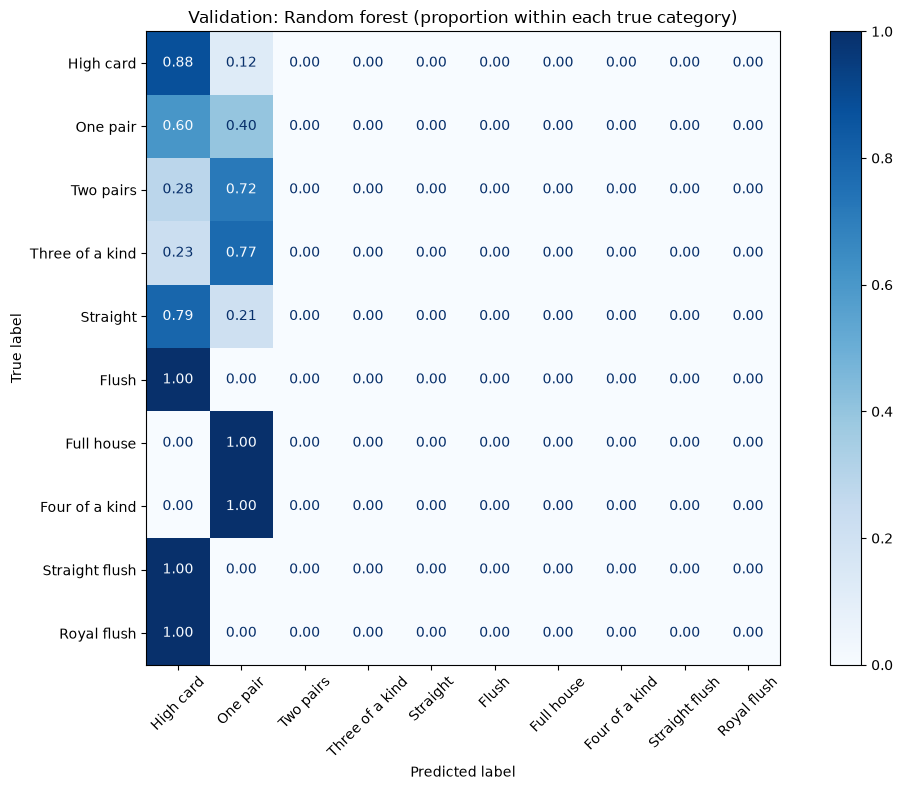

In [7]:
selected_prediction = validation_predictions[selected_name]
print(classification_report(
    y_validation,
    selected_prediction,
    labels=CLASS_CODES,
    target_names=[CLASS_LABELS[code] for code in CLASS_CODES],
    digits=3,
    zero_division=0,
))

fig, ax = plt.subplots(figsize=(11, 8))
ConfusionMatrixDisplay.from_predictions(
    y_validation,
    selected_prediction,
    labels=CLASS_CODES,
    display_labels=[CLASS_LABELS[code] for code in CLASS_CODES],
    normalize="true",
    cmap="Blues",
    xticks_rotation=45,
    values_format=".2f",
    ax=ax,
)
ax.set_title(f"Validation: {selected_name} (proportion within each true category)")
fig.tight_layout()
plt.show()

## 7. Optional final test evaluation

Leave `RUN_FINAL_TEST = False` while choosing models and settings. When the model and evaluation procedure are fixed, set it to `True` and run this cell.

This refits the selected pipeline on all distinct development hands. It reads the supplied million-row test file in chunks and reports:
1. Results on the full supplied test file.
2. Results on test records whose unordered hand did not appear in development.

The second report helps assess performance on unseen hands. It still weights individual records and does not remove repeated hands within the test file or group suit-renamed equivalents. Record the overlap count and limitations. Do not tune the model using these final results.

In [8]:
RUN_FINAL_TEST = False

if RUN_FINAL_TEST:
    final_model = clone(selected_model)
    final_model.fit(X_development, y_development)

    seen_development_keys = set(development_keys)
    true_parts = []
    prediction_parts = []
    unseen_parts = []

    with zipfile.ZipFile(archive_path) as archive:
        with archive.open("poker-hand-testing.data") as file:
            for chunk in pd.read_csv(
                file, header=None, names=COLUMNS, chunksize=50_000
            ):
                validate_records(chunk)
                chunk_keys = unordered_hand_keys(chunk)
                unseen = ~chunk_keys.isin(seen_development_keys)
                prediction = final_model.predict(chunk[FEATURE_COLUMNS])
                true_parts.append(chunk["CLASS"].to_numpy(dtype=np.uint8))
                prediction_parts.append(np.asarray(prediction, dtype=np.uint8))
                unseen_parts.append(unseen.to_numpy())

    y_test = np.concatenate(true_parts)
    test_prediction = np.concatenate(prediction_parts)
    unseen_mask = np.concatenate(unseen_parts)
    print(f"Test records: {len(y_test):,}")
    print(f"Records matching a development hand: {(~unseen_mask).sum():,}")

    for label, mask in [
        ("Full supplied test file", np.ones(len(y_test), dtype=bool)),
        ("Test hands absent from development", unseen_mask),
    ]:
        print(f"\n{label}: {mask.sum():,} records")
        if not mask.any():
            print("No records available for this report.")
            continue
        print(f"Accuracy: {accuracy_score(y_test[mask], test_prediction[mask]):.4f}")
        print("Macro F1:", round(f1_score(
            y_test[mask],
            test_prediction[mask],
            labels=CLASS_CODES,
            average="macro",
            zero_division=0,
        ), 4))
        print(classification_report(
            y_test[mask],
            test_prediction[mask],
            labels=CLASS_CODES,
            target_names=[CLASS_LABELS[code] for code in CLASS_CODES],
            digits=3,
            zero_division=0,
        ))
else:
    print("Final test evaluation skipped. Use validation results for development.")

Final test evaluation skipped. Use validation results for development.


## 8. Predict the category of a new hand

Supply the same ten input columns used during training. This example contains a pair of tens. Suit codes are 1=hearts, 2=spades, 3=diamonds, and 4=clubs.

The example uses the final model if final evaluation was enabled, otherwise the model fitted on the training split. A single prediction is a demonstration, not a performance measurement. The model retains positional inputs, so changing card order may change its answer.

In [9]:
new_hand = pd.DataFrame(
    [[1, 10, 2, 10, 3, 2, 4, 7, 1, 13]],
    columns=FEATURE_COLUMNS,
)
# Reuse the input checks; CLASS is supplied here only as a validation placeholder.
validate_records(new_hand.assign(CLASS=0))

prediction_model = final_model if RUN_FINAL_TEST else selected_model
predicted_code = int(prediction_model.predict(new_hand)[0])
display(new_hand)
print("Model:", selected_name)
print("Predicted category:", CLASS_LABELS[predicted_code])
print("Actual category for this example: One pair")

,S1,C1,S2,C2,S3,C3,S4,C4,S5,C5
0,1,10,2,10,3,2,4,7,1,13


Model: Random forest
Predicted category: High card
Actual category for this example: One pair


## 9. What to write in the report

Record the duplicate removal count, split sizes and class counts, random seed, package versions, encoding, model settings, validation comparison, selected model, and final results if evaluated. Discuss common versus rare categories, the baseline comparison, overfitting, overlap, and the uncertainty caused by very small class counts.

Possible next experiments include consistent card ordering, order-independent features, and feasible repeated validation. Explain whether engineered features directly encode the poker labeling rules. A correct rule-based evaluator is a useful reference because the hand category is determined by the cards.

**Sources**
- [UCI Poker Hand dataset](https://archive.ics.uci.edu/dataset/158/poker+hand): Cattral, R. and Oppacher, F. (2002), DOI: 10.24432/C5KW38.
- [scikit-learn: preventing data leakage](https://scikit-learn.org/stable/common_pitfalls.html).
- [scikit-learn: stratified train/validation splitting](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html).
- [scikit-learn: random forest classifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html).
- [scikit-learn: classification report](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html).

**AI assistance disclosure:** OpenAI Codex assisted in creating this training notebook. Review and explain the methods, verify results in the team's environment, and complete the course's required attribution.